# Preprocessing Data: Retail Dirty Transactions
Tahap pembersihan data transaksi ritel yang memuat anomali dan data kotor.


### 1. Import Library


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


**Penjelasan:** Mengimpor library pandas, numpy, matplotlib, dan seaborn.


### 2. Load Dataset


In [2]:
import os

file_path = 'retail_transactions_5500_dirty.csv'
url = 'https://raw.githubusercontent.com/Firdaus1802/data-preprocessing/main/03_Retail_Dirty_Transactions/retail_transactions_5500_dirty.csv'

df = pd.read_csv(file_path if os.path.exists(file_path) else url)


**Penjelasan:** Dataset transaksi ritel berhasil dimuat.


### 3. Menampilkan 5 Data Teratas


In [3]:
df.head()


,InvoiceNo,Description,Quantity
0,INV1603,Biscuits,2
1,INV1119,Wheat Flour,3
2,INV1652,Wheat Flour,5
3,INV1467,Sugar,2
4,CINV1357,Detergent,4


**Penjelasan:** Menampilkan 5 baris pertama data transaksi.


### 4. Menampilkan 5 Data Terbawah


In [4]:
df.tail()


,InvoiceNo,Description,Quantity
5495,INV1526,Salt,4
5496,INV1088,Detergent,5
5497,INV1377,Bread,5
5498,CINV1068,Chocolate,3
5499,INV1406,Toothpaste,1


**Penjelasan:** Menampilkan 5 baris terakhir data transaksi.


### 5. Jumlah Baris


In [5]:
print('Jumlah Baris:', len(df))


Jumlah Baris: 5500


**Penjelasan:** Dataset memiliki total 5.500 baris data.


### 6. Jumlah Kolom


In [6]:
print('Jumlah Kolom:', len(df.columns))


Jumlah Kolom: 3


**Penjelasan:** Terdapat 3 kolom atribut (InvoiceNo, Description, Quantity).


### 7. Info Dataset


In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   InvoiceNo    5500 non-null   str  
 1   Description  5221 non-null   str  
 2   Quantity     5500 non-null   int64
dtypes: int64(1), str(2)
memory usage: 129.0 KB


**Penjelasan:** Kolom terdiri dari 2 tipe teks dan 1 tipe integer.


### 8. Cek Missing Value


In [8]:
df.isnull().sum()


InvoiceNo        0
Description    279
Quantity         0
dtype: int64

**Penjelasan:** Ditemukan 279 missing value pada kolom Description.


### 9. Total Missing Value


In [9]:
print('Total Missing Value:', df.isnull().sum().sum())


Total Missing Value: 279


**Penjelasan:** Total missing value adalah 279 data.


### 10. Persentase Missing Value


In [10]:
persen = (df.isnull().sum().sum() / (len(df) * len(df.columns))) * 100
print(f'Persentase Missing Value: {persen:.2f}%')


Persentase Missing Value: 1.69%


**Penjelasan:** Persentase data kosong adalah 1,69% dari total seluruh sel.


### 11. Heatmap Missing Value Sebelum Imputasi


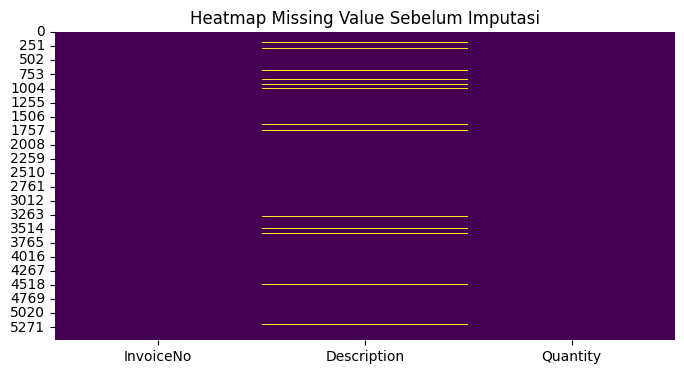

In [11]:
plt.figure(figsize=(8, 4))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Heatmap Missing Value Sebelum Imputasi')
plt.show()


**Penjelasan:** Garis kuning pada kolom Description menunjukkan letak 279 data kosong.


### 12. Imputasi Missing Value


In [12]:
# Mengisi missing value Description dengan label UNKNOWN_ITEM
df['Description'] = df['Description'].fillna('UNKNOWN_ITEM')
print('Sisa Missing Value:', df.isnull().sum().sum())


Sisa Missing Value: 0


**Penjelasan:** Nilai kosong pada Description diisi dengan label 'UNKNOWN_ITEM'. Data sekarang sudah lengkap tanpa missing value.


### 13. Heatmap Missing Value Setelah Imputasi


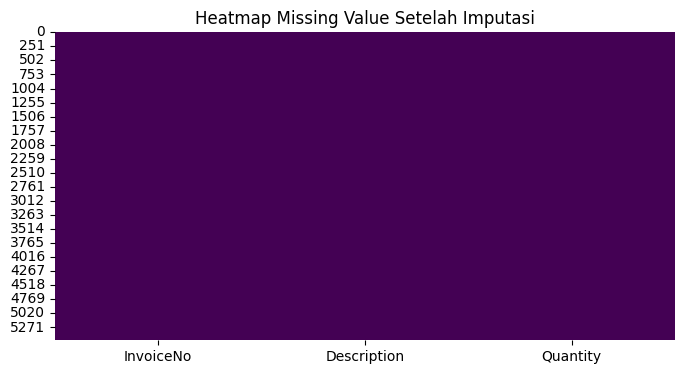

In [13]:
plt.figure(figsize=(8, 4))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Heatmap Missing Value Setelah Imputasi')
plt.show()


**Penjelasan:** Heatmap sekarang berwarna ungu solid tanpa ada data kosong.


### 14. Cek Data Duplikat


In [14]:
print('Jumlah Baris Duplikat:', df.duplicated().sum())


Jumlah Baris Duplikat: 114


**Penjelasan:** Ditemukan 114 baris data duplikat.


### 15. Hapus Data Duplikat


In [15]:
# Menghapus baris data duplikat
df = df.drop_duplicates()
print('Jumlah Duplikat Setelah Dihapus:', df.duplicated().sum())
print('Total Baris Sekarang:', len(df))


Jumlah Duplikat Setelah Dihapus: 0
Total Baris Sekarang: 5386


**Penjelasan:** Sebanyak 114 baris duplikat berhasil dihapus menggunakan fungsi drop_duplicates(), sehingga sekarang tidak ada lagi data duplikat dan tersisa 5.386 baris data.


### 16. Cek Faktur Unik


In [16]:
print('Jumlah Faktur Unik:', df['InvoiceNo'].nunique())


Jumlah Faktur Unik: 1201


**Penjelasan:** Terdapat 1.201 faktur unik (InvoiceNo).


### 17. Produk Terpopuler


In [17]:
df['Description'].value_counts().head(10)


Description
Cooking Oil     289
Sugar           278
UNKNOWN_ITEM    274
Shampoo         273
Toothpaste      270
Detergent       269
Jam             269
Wheat Flour     267
Spices          263
Bread           263
Name: count, dtype: int64

**Penjelasan:** Menampilkan 10 produk dengan transaksi pembelian terbanyak.


### 18. Hitung Ukuran Keranjang Belanja


In [18]:
item_per_invoice = df.groupby('InvoiceNo')['Description'].count()


**Penjelasan:** Menghitung banyaknya item produk yang dibeli per faktur belanja.


### 19. Statistik Deskriptif Ukuran Keranjang


In [19]:
item_per_invoice.describe()


count    1201.000000
mean        4.484596
std         2.934843
min         1.000000
25%         2.000000
50%         4.000000
75%         7.000000
max        16.000000
Name: Description, dtype: float64

**Penjelasan:** Rata-rata ukuran keranjang adalah 4,48 item dengan nilai maksimum 16 item.


### 20. Boxplot Ukuran Keranjang


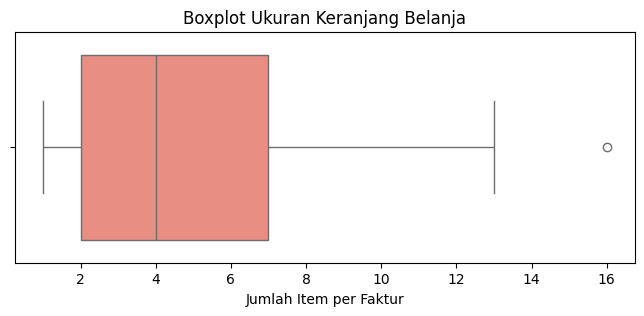

In [20]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=item_per_invoice, color='salmon')
plt.title('Boxplot Ukuran Keranjang Belanja')
plt.xlabel('Jumlah Item per Faktur')
plt.show()


**Penjelasan:** Boxplot memperlihatkan sebagian besar transaksi membeli antara 2 sampai 7 jenis barang.


### 21. Hitung Kuartil dan IQR


In [21]:
Q1 = item_per_invoice.quantile(0.25)
Q3 = item_per_invoice.quantile(0.75)
IQR = Q3 - Q1

print('Q1 :', Q1)
print('Q3 :', Q3)
print('IQR:', IQR)


Q1 : 2.0
Q3 : 7.0
IQR: 5.0


**Penjelasan:** Nilai Q1 = 2, Q3 = 7, dan IQR = 5.


### 22. Hitung Batas Atas Outlier


In [22]:
batas_atas = Q3 + (1.5 * IQR)
print('Batas Atas Outlier:', batas_atas)


Batas Atas Outlier: 14.5


**Penjelasan:** Batas atas outlier adalah 14,5 item. Transaksi di atas 14,5 item tergolong outlier.


### 23. Jumlah Data Outlier


In [23]:
outlier = item_per_invoice[item_per_invoice > batas_atas]
print('Jumlah Outlier:', len(outlier))


Jumlah Outlier: 1


**Penjelasan:** Ditemukan 1 transaksi outlier yang membeli 16 jenis barang.


### 24. Daftar Transaksi Outlier Terbesar


In [24]:
outlier.sort_values(ascending=False).head()


InvoiceNo
INV1467    16
Name: Description, dtype: int64

**Penjelasan:** Transaksi outlier tersebut adalah faktur INV1467 dengan 16 item barang.
